# Market Risk Quantification: Value at Risk (VaR) via Monte Carlo Simulation on the BSE Sensex
*Monte Carlo Methods in Finance: course project (report: `Monte_Carlo_course_report.pdf`, 17-Feb-2026)*

Risk management in banking follows three steps: **Identify, Quantify, Mitigate**. Under Basel II the leverage ratio (capital / total assets) must stay above 4%. VaR quantifies how much capital must be set aside to support a trading position.

> v1 of the project. Version 2 (`Sensex_Monte_Carlo_VaR.ipynb`) reviews and extends this model.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy.stats
from matplotlib import style
style.use('ggplot')

### Data Setup and EDA
Daily OHLC data for the BSE Sensex, Jan 2016 to Mar 2021. If `Sensex.csv` is not present, the same window is downloaded from Yahoo Finance in the same format.

In [2]:
if os.path.exists('/content/Sensex.csv') or os.path.exists('Sensex.csv'):
    index_data = pd.read_csv('/content/Sensex.csv' if os.path.exists('/content/Sensex.csv') else 'Sensex.csv')
else:
    import yfinance as yf
    raw = yf.Ticker('^BSESN').history(start='2016-01-01', end='2021-03-24', auto_adjust=False)
    index_data = raw[['Open', 'High', 'Low', 'Close']].round(2).reset_index()
    index_data['Date'] = [f"{d.day}-{d:%b-%y}" for d in index_data['Date']]
index_data.head()

,Date,Open,High,Low,Close
0,4-Jan-16,26116.52,26116.52,25596.57,25623.35
1,5-Jan-16,25744.70,25766.76,25513.75,25580.34
2,6-Jan-16,25628.23,25632.57,25357.70,25406.33
3,7-Jan-16,25224.70,25230.35,24825.70,24851.83
4,8-Jan-16,24969.02,25083.55,24887.22,24934.33


In [3]:
index_data.tail()

,Date,Open,High,Low,Close
1280,17-Mar-21,50436.02,50561.12,49718.65,49801.62
1281,18-Mar-21,50161.25,50296.35,48962.36,49216.52
1282,19-Mar-21,48881.19,50003.58,48586.93,49858.24
1283,22-Mar-21,49878.77,49878.77,49281.02,49771.29
1284,23-Mar-21,49876.21,50264.65,49661.92,50051.44


In [4]:
index_data['Close'].tail()

1280    49801.62
1281    49216.52
1282    49858.24
1283    49771.29
1284    50051.44
Name: Close, dtype: float64

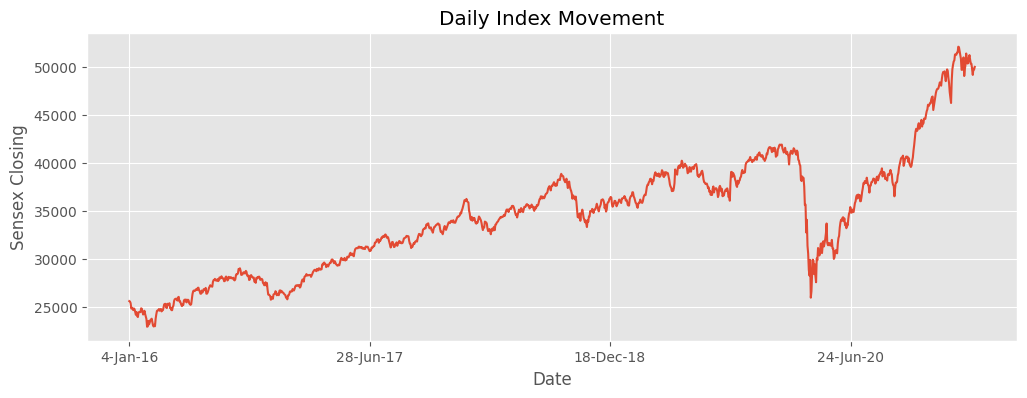

In [5]:
fig,ax=plt.subplots(figsize=(12,4))

ax.plot(index_data['Date'],index_data['Close'])
ax.set(xlabel='Date',ylabel='Sensex Closing',title='Daily Index Movement')
ax.xaxis.set_major_locator(mdates.YearLocator())

In [6]:
index_returns=index_data['Close'].pct_change()
index_returns.head()

0         NaN
1   -0.001679
2   -0.006802
3   -0.021825
4    0.003320
Name: Close, dtype: float64

In [7]:
nornal_returns=(np.random.normal(0,index_returns.dropna().std(),len(index_data)))

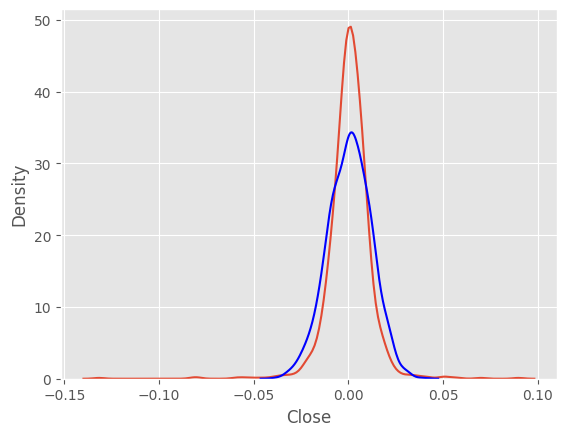

In [8]:
fig,ax=plt.subplots()
sns.kdeplot(index_returns.dropna(),ax=ax);
sns.kdeplot(nornal_returns,color='b',ax=ax);

The daily Sensex returns are approximately normally distributed, but with outliers. The distribution is roughly symmetric about the mean, but the tails are fatter than a normal distribution would predict.

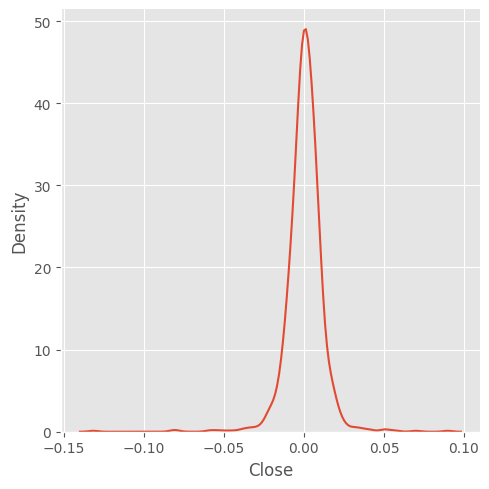

In [9]:
sns.displot(index_returns.dropna(),kind='kde');

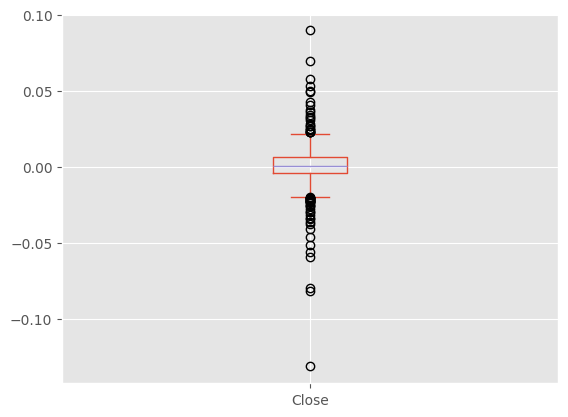

In [10]:
index_returns.plot(kind='box');

In [11]:
outlier_data=index_data[(index_returns<-0.05) | (index_returns>0.05)]
outlier_data

,Date,Open,High,Low,Close
913,20-Sep-19,36214.92,38378.02,36085.74,38014.62
1026,9-Mar-20,36950.20,36950.20,35109.18,35634.95
1028,12-Mar-20,34472.50,34472.50,32493.10,32778.14
1030,16-Mar-20,33103.24,33103.24,31276.30,31390.07
1032,18-Mar-20,30968.84,31101.77,28613.05,28869.51
1034,20-Mar-20,28460.82,30418.20,27932.67,29915.96
1035,23-Mar-20,27608.80,27900.83,25880.83,25981.24
1037,25-Mar-20,26499.81,28790.19,26359.91,28535.78
1044,7-Apr-20,28898.36,30157.65,28602.31,30067.21
1060,4-May-20,32748.14,32748.14,31632.02,31715.35


In [12]:
outlier_data=outlier_data.reset_index()
outlier_data['Previous Close']=0.0
for i in range(len(outlier_data)):
    outlier_data.iloc[i,6]=index_data.iloc[outlier_data['index'][i]-1]['Close']
outlier_data

,index,Date,Open,High,Low,Close,Previous Close
0,913,20-Sep-19,36214.92,38378.02,36085.74,38014.62,36093.47
1,1026,9-Mar-20,36950.20,36950.20,35109.18,35634.95,37576.62
2,1028,12-Mar-20,34472.50,34472.50,32493.10,32778.14,35697.40
3,1030,16-Mar-20,33103.24,33103.24,31276.30,31390.07,34103.48
4,1032,18-Mar-20,30968.84,31101.77,28613.05,28869.51,30579.09
5,1034,20-Mar-20,28460.82,30418.20,27932.67,29915.96,28288.23
6,1035,23-Mar-20,27608.80,27900.83,25880.83,25981.24,29915.96
7,1037,25-Mar-20,26499.81,28790.19,26359.91,28535.78,26674.03
8,1044,7-Apr-20,28898.36,30157.65,28602.31,30067.21,27590.95
9,1060,4-May-20,32748.14,32748.14,31632.02,31715.35,33717.62


##### Outlier data can be further investigated for the reason for the daily returns more than +/- 5%
### Simulation
Geometric Brownian Motion, $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, discretised with negligible daily drift ($\mu \approx 0$):

$$S_{t+1} = S_t(1 + \sigma Z), \qquad Z \sim N(0,1)$$

1,000 independent paths are simulated over a 252-day horizon.

In [13]:
last_price=index_data['Close'].iloc[-1]
num_simulations=1000
num_days=252
last_price

np.float64(50051.44)

In [14]:
simulated_data=pd.DataFrame()

for x in range(num_simulations):
    count=0
    daily_volatility=index_returns.std()

    price_series=[]

    price=last_price*(1+np.random.normal(0,daily_volatility))
    price_series.append(price)

    for y in range(num_days):
        if count==251:
            break
        price=price_series[count]*(1+np.random.normal(0,daily_volatility))
        price_series.append(price)
        count+=1

    simulated_data[x]=price_series

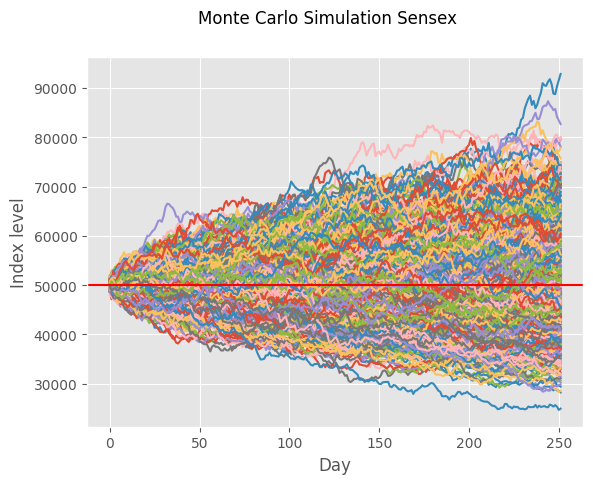

In [15]:
fig=plt.figure()
fig.suptitle('Monte Carlo Simulation Sensex')
plt.plot(simulated_data)
plt.axhline(y=last_price,color='r',linestyle='-')
plt.xlabel('Day')
plt.ylabel('Index level')
plt.show()

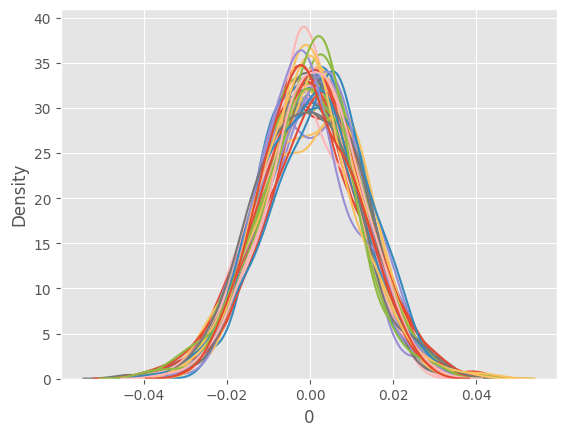

In [16]:
fig, ax = plt.subplots()
for i in range(50):
    sns.kdeplot(simulated_data[i].pct_change().dropna(),ax=ax)

#### Distribution of returns of the first 50 simulated samples
### VaR - Value At Risk
$$VaR = \text{Position} \times \sigma_{daily} \times Z_{1-\alpha}$$

VaR can be interpreted as: we are 95% confident that the daily loss will not exceed the VaR amount.

In [17]:
alpha=scipy.stats.norm.ppf(0.95)
position=100000
var=position*index_returns.dropna().std()*alpha
print(f'z-score at 95%: {alpha:.4f}')
print(f'Daily VaR on a position of {position:,}: {var:,.2f}')

z-score at 95%: 1.6449
Daily VaR on a position of 100,000: 1,915.78


#### VaR is the additional capital needed to support the position.
### Stress Testing
The simulation uses the standard deviation of daily returns as the measure of volatility. What if volatility increases? How much additional capital would the bank need to support its position?

In [18]:
daily_volatility=index_returns.std()
print(f'Daily volatility of the market index returns is {daily_volatility}')
print(f'Annualised volatility of the market index returns is {(((1+daily_volatility)**12)-1)*100} %')

Daily volatility of the market index returns is 0.011647126909631354
Annualised volatility of the market index returns is 14.90756709781762 %


In [19]:
# If the market index return volatility increases to 20%
daily_vol_20=((0.20+1)**(1/12))-1
print(f'For yearly volatility of 20%, the daily volatility of the index returns is {daily_vol_20}')
var_20=position*daily_vol_20*alpha
print(f'Daily VaR at yearly volatility of 20% is {var_20}')

For yearly volatility of 20%, the daily volatility of the index returns is 0.015309470499731193
Daily VaR at yearly volatility of 20% is 2518.1838078189417


In [20]:
# If the market index return volatility increases to 25%
daily_vol_25=((0.25+1)**(1/12))-1
print(f'For yearly volatility of 25%, the daily volatility of the index returns is {daily_vol_25}')
var_25=position*daily_vol_25*alpha
print(f'Daily VaR at yearly volatility of 25% is {var_25}')

For yearly volatility of 25%, the daily volatility of the index returns is 0.018769265121506118
Daily VaR at yearly volatility of 25% is 3087.2693810323103


### VaR Simulation

In [21]:
simulated_volatality=pd.DataFrame(columns=['simulated_volatality','simulated_var'])
for x in range(num_simulations):
    simulated_volatality.loc[x,'simulated_volatality']=simulated_data.iloc[:,x].pct_change().std()
    simulated_volatality.loc[x,'simulated_var']=position*simulated_volatality.loc[x,'simulated_volatality']*alpha
simulated_volatality.head()

,simulated_volatality,simulated_var
0,0.011211,1844.06705
1,0.011364,1869.138984
2,0.011626,1912.243705
3,0.012446,2047.266064
4,0.011521,1894.977154


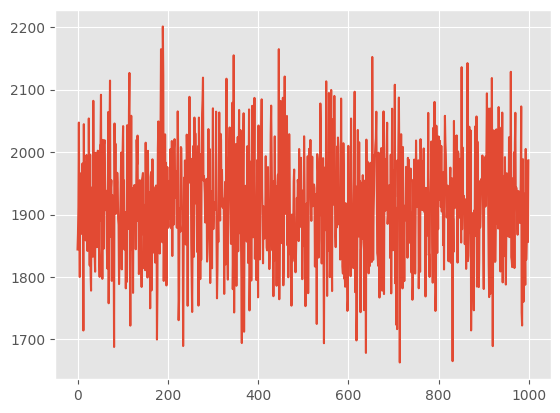

In [22]:
plt.plot(simulated_volatality['simulated_var']);

In [23]:
mean_simulated_var=np.mean(simulated_volatality['simulated_var'])
stand_dev_simulated_var=np.std(simulated_volatality['simulated_var'])
print(f'Simulated average daily VaR is {mean_simulated_var} with standard deviation of {stand_dev_simulated_var}')

Simulated average daily VaR is 1915.5034700210992 with standard deviation of 88.45365536329088


### Conclusion
By modelling the BSE Sensex as a discrete random walk and running stress tests, we quantified the capital needed to support a 100,000 position under normal and stressed volatility regimes.